#### Dimensões da malha

Os pontos medidos foram x=19cm e y=19cm. Vamos adotar uma escala de 10 pontos por centímetro para o cálculo.

In [189]:
import matplotlib.pyplot as plt
import numpy as np

escala = 10
Nx = int(19 * escala)
Ny = int(19 * escala)

#### Inicialização matriz de potencial e eletrodos

O método irá calcular o valor de tensão em cada ponto da matriz. Inicializamos como 5V para que a matriz não comece inteira zerada, evitando uma convergência falsa logo nas primeiras iterações.

Em seguida, configuramos a geometria do sistema utilizando uma escala de de pontos por centimetro. As regiões correspondentes aos dois eletrodos em formato de barra são delimitadas com base nas coordenadas físicas e armazenadas em uma matriz booleana denominada "eletrons". Dessa forma, os potenciais dos eletrodos são fixados nessas regiões e travados a cada passo do algoritmo, impedindo que o método iterativo altere os valores metálicos.

In [190]:
V = np.ones((Ny, Nx)) * 5.0

eletrodos = np.zeros((Ny, Nx), dtype=bool)

y_ini = int(5.5 * escala)
y_fim = int(13.5 * escala)

# Eletrodo esquerdo (10V)
x1_ini = int(5.2 * escala)
x1_fim = int(6.0 * escala)
V[y_ini:y_fim, x1_ini:x1_fim] = 0.0
eletrodos[y_ini:y_fim, x1_ini:x1_fim] = True

# Eletrodo direito (0V)
x2_ini = int(13.0 * escala)
x2_fim = int(13.8 * escala)
V[y_ini:y_fim, x2_ini:x2_fim] = 10.0
eletrodos[y_ini:y_fim, x2_ini:x2_fim] = True

# y_ini = int(5.5 * escala)
# y_fim = int(13.5 * escala)

# # Eletrodo esquerdo (10V)
# x1_ini = int(0 * escala)
# x1_fim = int(0.8 * escala)
# V[y_ini:y_fim, x1_ini:x1_fim] = 0.0
# eletrodos[y_ini:y_fim, x1_ini:x1_fim] = True

# # Eletrodo direito (0V)
# x2_ini = int(18.2 * escala)
# x2_fim = int(19 * escala)
# V[y_ini:y_fim, x2_ini:x2_fim] = 10.0
# eletrodos[y_ini:y_fim, x2_ini:x2_fim] = True


In [191]:

# LOOP DE ITERAÇÃO (Garante que rode pelo menos 3000 vezes para espalhar o campo)
error = 1.0
tolerance = 0.01
iteration = 0

while error > tolerance or iteration < 3000:
# while error > tolerance:
  V_old = V.copy()

  # Atualiza toda a malha interna (MDF)
  V[1:-1, 1:-1] = 0.25 * (
      V_old[2:, 1:-1] + V_old[:-2, 1:-1] + V_old[1:-1, 2:] + V_old[1:-1, :-2]
  )

  # --- PAREDES ISOLANTES (Condição de Neumann nas bordas) ---
  V[0, :] = V[1, :]
  V[-1, :] = V[-2, :]
  V[:, 0] = V[:, 1]
  V[:, -1] = V[:, -2]

  # Re-trava os eletrodos
  V[y_ini:y_fim, x1_ini:x1_fim] = 0.0
  V[y_ini:y_fim, x2_ini:x2_fim] = 10.0

  # Cálculo do erro (ignorando os eletrodos fixos para maior precisão)
  # Criamos uma máscara onde apenas os pontos não-eletrodos contam para o erro
  diff = np.abs(V - V_old)
  diff[eletrodos] = 0.0
  error = np.sum(diff) / np.sum(~eletrodos)

  iteration += 1

print(
    f"Simulação concluída após {iteration} iterações. Erro final: {error:.5f} V"
)

Simulação concluída após 3000 iterações. Erro final: 0.00023 V


#### Plota as curvas equipotenciais

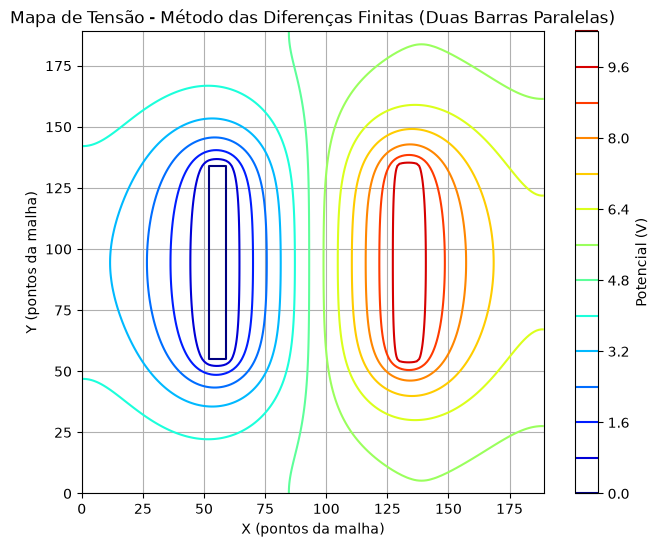

In [192]:
plt.figure(figsize=(8, 6))
cp = plt.contour(V, levels=15, cmap="jet")
plt.colorbar(cp, label="Potencial (V)")
plt.title(
    "Mapa de Tensão - Método das Diferenças Finitas (Duas Barras Paralelas)"
)
plt.xlabel("X (pontos da malha)")
plt.ylabel("Y (pontos da malha)")
plt.grid(True)
plt.gca().set_aspect("equal")
plt.show()